![Python Banner](../../Image/05_08_Quasi_Experiemnts.png)


# 8.1 Difference-in-Differences (DiD)



Difference-in-Differences (DiD) is one of the most widely used quasi-experimental methods in business and policy evaluation. It compares the change in outcomes over time between a treatment group and a control group to estimate causal effects.

## Overview

### The Core Idea

DiD removes two kinds of bias simultaneously:

1. **Level differences** between treated and control groups (e.g., flagship markets are naturally larger)
2. **Common time shocks** (seasonality, macro conditions, company-wide changes)

The basic DiD estimator is:

$$
\hat{\tau}_{DiD} = \big(\bar{Y}^{T}_{post} - \bar{Y}^{T}_{pre}\big) - \big(\bar{Y}^{C}_{post} - \bar{Y}^{C}_{pre}\big)
$$

This is literally the difference in differences: the treated group's change minus the control group's change.

### Business Setting

DiD is ideal when:

- Treatment is assigned to **some groups** (markets, stores, customer segments) at a **known point in time**
- Other groups remain **untreated throughout** the observation period
- You have **pre- and post-period outcomes** for both groups

Common business examples:

- A new store format launches in select markets
- A pricing change applies to certain product categories
- A marketing campaign runs in specific regions
- A training program is rolled out to some departments

### The Identifying Assumption: Parallel Trends

The critical assumption for DiD is **parallel trends**: absent the treatment, the treated and control groups would have followed the same trajectory over time. Level differences are fine — they cancel out when we take differences. But differential *trends* are fatal.

**Important**: Parallel trends cannot be proven — it is a claim about an unobservable counterfactual. However, we can probe it by checking that the groups moved in parallel during the pre-treatment period and that divergence occurs precisely at the intervention date.

### When DiD Breaks

DiD fails when:

- Treated and control groups had **different pre-treatment trends** (e.g., a struggling division gets the intervention)
- Something **else happens to only the treated group** at the same time as the intervention (common in business where events cluster geographically)
- Treatment timing is **staggered** (groups adopt at different times) with dynamic effects — standard two-way fixed effects regression can produce biased estimates in this case (see the note on staggered adoption below. Chapter 6.5 puts a Bayesian interval on this same regression)

### Key Advantages

- **Intuitive**: Easy to explain to non-technical stakeholders
- **Transparent**: The parallel trends assumption is clear and can be visually checked
- **Flexible**: Works with panel data (multiple units over time) and repeated cross-sections
- **Robust**: Handles many confounders as long as they affect both groups similarly over time


## Implementation in Python

`DifferenceInDifferences` fits $Y = a + b\,\mathrm{treated} + c\,\mathrm{post} + \tau\,\mathrm{treated}\times\mathrm{post}$ and returns a Bayesian bootstrap interval for $\tau$. A two-way within estimator is also computed on the simulated panel, because store and week shocks are part of that design. The bootstrap resamples rows. It does not replace clustering at the market, which still matters when only a few markets are treated.

The setup matches the other PyCausalML tutorials: find the repository, import the package, and install the editable checkout only if the import fails.

## Set Up


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()

try:
    import pycausalml  # noqa: F401
    print("PyCausalML ready.")
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot]"],
    )
    print("PyCausalML installed.")
print("Repository:", root)


PyCausalML ready.
Repository: /home/zia207/Github/PyCausalML


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pycausalml import (
    DifferenceInDifferences,

)

rng = np.random.default_rng(42)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print("Imported PyCausalML")


Imported PyCausalML


## Simulated Example: Store-Level Rollout

We'll simulate a retail scenario where a new program launches in some markets but not others. This lets us know the true effect and verify that DiD recovers it.

In [3]:
def make_panel(
    n_stores=120,
    n_markets=12,
    n_weeks=104,                # 2 years of weekly data
    treat_markets=(0, 1, 2, 3), # which markets get the program
    treat_week=60,              # program launch week
    true_effect=8.0,            # true lift in weekly revenue ($k)
    effect_ramp=6,              # weeks for the effect to reach full size
    seed=42,
):
    """Simulate store-week panel data with a known treatment effect."""
    rng = np.random.default_rng(seed)
    stores = np.arange(n_stores)
    markets = stores % n_markets
    
    # Store and market fixed effects
    store_fe = rng.normal(100, 15, n_stores)
    market_fe = rng.normal(0, 8, n_markets)
    store_trend = rng.normal(0.05, 0.03, n_stores)
    
    rows = []
    market_shock = rng.normal(0, 3, (n_markets, n_weeks))
    
    for w in range(n_weeks):
        season = 6 * np.sin(2 * np.pi * w / 52)  # yearly seasonality
        for s in stores:
            m = markets[s]
            treated_unit = m in treat_markets
            post = w >= treat_week
            
            # Treatment effect ramps in over effect_ramp weeks
            if treated_unit and post:
                ramp = min(1.0, (w - treat_week + 1) / effect_ramp)
                tau = true_effect * ramp
            else:
                tau = 0.0
            
            # Revenue outcome
            y = (store_fe[s] + market_fe[m] + store_trend[s] * w
                 + season + market_shock[m, w]
                 + tau + rng.normal(0, 4))
            
            rows.append((s, m, w, int(treated_unit), int(post),
                         int(treated_unit and post), y))
    
    return pd.DataFrame(rows, columns=[
        "store", "market", "week", "treated", "post", "D", "revenue"])

# Generate the panel
panel = make_panel()
print(panel.head())
print("\nTrue effect at full ramp: $8k/week")


   store  market  week  treated  post  D  revenue
0      0       0     0        1     0  0   99.304
1      1       1     0        1     0  0   84.039
2      2       2     0        1     0  0  119.259
3      3       3     0        1     0  0  129.004
4      4       4     0        0     0  0   75.000

True effect at full ramp: $8k/week


Key columns:

- `treated` — 1 if the store belongs to a market that *ever* receives the program
- `post` — 1 for weeks at or after launch
- `D = treated × post` — the actual treatment status in each store-week
- `revenue` — the outcome we're analyzing

## The 2×2 DiD Estimator

Let's start with the simplest approach: compute the 2×2 table of means and take the difference in differences.

In [4]:
# Group by treatment status and time period
g = (panel.groupby(["treated", "post"]).revenue.mean()
          .unstack("post"))
g.columns = ["pre", "post"]
g["change"] = g["post"] - g["pre"]

print(g)

# DiD estimate
did_2x2 = g.loc[1, "change"] - g.loc[0, "change"]
print(f"\n2×2 DiD estimate: ${did_2x2:.2f}k/week")
print("(True effect at full ramp: $8k/week)")

            pre    post  change
treated                        
0        99.069 101.205   2.136
1       101.875 110.678   8.803

2×2 DiD estimate: $6.67k/week
(True effect at full ramp: $8k/week)


Note that the estimate is below $8k because the effect ramps up over 6 weeks — the post-period *average* effect is diluted by the ramp. This is realistic: business interventions rarely hit full strength instantly.

## Regression DiD with Two-Way Fixed Effects

The regression form generalizes the 2×2, allows covariates, and produces standard errors:

$$
Y_{it} = \alpha_i + \lambda_t + \tau \, D_{it} + \varepsilon_{it}
$$

where:
- $\alpha_i$ are store fixed effects (controls for time-invariant differences between stores)
- $\lambda_t$ are week fixed effects (controls for time shocks affecting all stores)
- $D_{it}$ is the store-week treatment indicator
- $\tau$ is the DiD coefficient — our causal effect estimate

In [5]:

did = DifferenceInDifferences(n_boot=200, rope=(-1.0, 1.0), random_state=0)
did.fit(panel["revenue"].to_numpy(), panel["treated"].to_numpy(), panel["post"].to_numpy())
print("Regression DiD:")
print(pd.Series(did.summary()).round(3))


def twfe_coefficient(frame, y, d, unit, time):
    """Treatment coefficient after removing unit means and time means."""
    work = frame[[y, d, unit, time]].copy()
    work["y_dm"] = (
        work[y]
        - work.groupby(unit)[y].transform("mean")
        - work.groupby(time)[y].transform("mean")
        + work[y].mean()
    )
    work["d_dm"] = (
        work[d]
        - work.groupby(unit)[d].transform("mean")
        - work.groupby(time)[d].transform("mean")
        + work[d].mean()
    )
    yd = work["y_dm"].to_numpy()
    dd = work["d_dm"].to_numpy()
    return float(np.dot(dd, yd) / np.dot(dd, dd))


tau_twfe = twfe_coefficient(panel, "revenue", "D", "store", "week")
print(f"Two-way fixed-effects coefficient: ${tau_twfe:.2f}k/week")
print("True full-ramp effect: $8k/week. The post-period average is smaller because the effect ramps in.")
print("The row bootstrap does not cluster by market. With four treated markets, read the interval as optimistic.")


Regression DiD:
estimate           6.668
ci_lower           5.484
ci_upper           7.809
posterior_mean     6.677
rope_probability   0.000
dtype: float64
Two-way fixed-effects coefficient: $6.67k/week
True full-ramp effect: $8k/week. The post-period average is smaller because the effect ramps in.
The row bootstrap does not cluster by market. With four treated markets, read the interval as optimistic.


### Three Practical Points

1. **Cluster standard errors at the level of treatment assignment** — here, the *market*, not the store. Treatment varies at the market level, so store-level errors within a market are correlated. Clustering at the store level would dramatically overstate precision.

2. **Few treated clusters is a real problem.** With only 4 treated markets, asymptotic clustered SEs are unreliable. Consider randomization/permutation inference or aggregate to the market level.

3. **Covariates should be pre-treatment or time-invariant.** Never add post-treatment variables (mediators) — this would bias the estimate by blocking part of the treatment effect.

## Testing Parallel Trends

Parallel trends cannot be tested directly — it's a statement about an unobserved counterfactual. But we can check pre-period trends: if the groups diverged before treatment, parallel trends is violated.

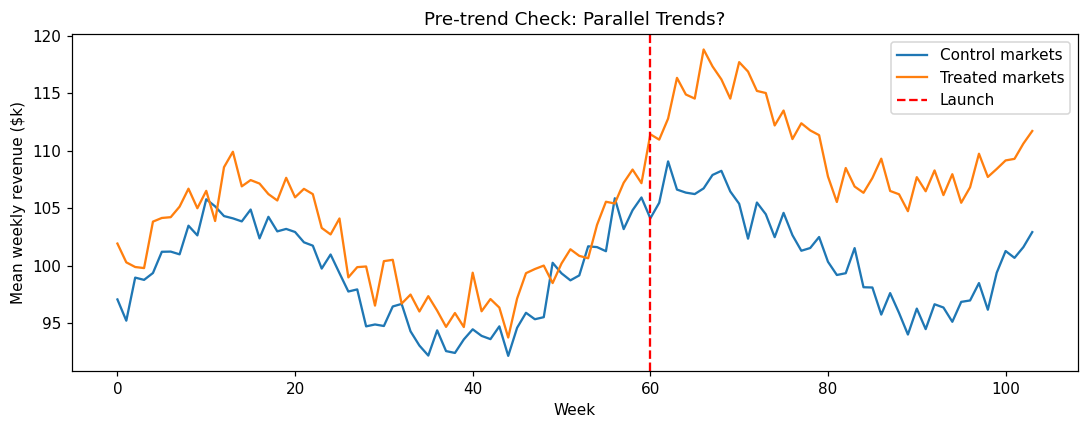

In [6]:
# Compute mean weekly revenue by group
trend = (panel.groupby(["week", "treated"]).revenue.mean()
              .unstack("treated"))

# Plot
ax = trend.plot(figsize=(10, 4))
ax.axvline(60, color="red", ls="--", label="Launch")
ax.set_ylabel("Mean weekly revenue ($k)")
ax.set_xlabel("Week")
ax.legend(["Control markets", "Treated markets", "Launch"])
plt.title("Pre-trend Check: Parallel Trends?")
plt.tight_layout()
plt.show()

The pre-period (weeks 0-59) should show the two lines moving in parallel. If they diverge before week 60, parallel trends is violated and DiD is biased.

A formal pre-trend test can be done by interacting the treatment indicator with leads (time before treatment):

In [7]:

pre = panel[panel["post"] == 0]
slopes = {}
for flag, group in pre.groupby("treated"):
    means = group.groupby("week")["revenue"].mean()
    slopes[int(flag)] = float(np.polyfit(means.index.to_numpy(float), means.to_numpy(), 1)[0])

print(f"Pre-period slope, control markets: {slopes[0]:.4f}")
print(f"Pre-period slope, treated markets: {slopes[1]:.4f}")
print(f"Slope gap (treated - control): {slopes[1] - slopes[0]:.4f}")
print("A gap near zero is the pre-period check on parallel trends.")


Pre-period slope, control markets: -0.0559
Pre-period slope, treated markets: -0.0779
Slope gap (treated - control): -0.0220
A gap near zero is the pre-period check on parallel trends.


If the lead coefficients are statistically significant, it suggests pre-existing divergence — a red flag for parallel trends.

## Staggered Adoption and Event Studies

In practice, business programs often roll out in waves, not all at once. This is called **staggered adoption**. With staggered timing and dynamic effects, the standard two-way fixed effects regression can produce biased estimates because it uses already-treated units as controls — introducing "forbidden comparisons."

Modern practice uses **event-study DiD**, which estimates effects at each time point relative to the intervention. This serves two purposes:

1. **Pre-trend test**: Leads (coefficients before treatment) should be near zero
2. **Dynamic trajectory**: Lags trace how the effect evolves over time

Chapter 6.5 fits this regression with the same Bayesian interval on a real banking panel. The pre-trend plot in this notebook is the event-study check for a single adoption date.


## Real-World Data

The series below is a real dataset shipped with [CausalPy](https://causalpy.readthedocs.io/en/stable/) (PyMC Labs), under the Apache License 2.0. The files live in [`causalpy/data`](https://github.com/pymc-labs/CausalPy/tree/main/causalpy/data).

```
@software{causalpy,
  author = {{PyMC Labs}},
  title = {CausalPy: Causal inference for quasi-experiments in Python},
  url = {https://github.com/pymc-labs/CausalPy},
  year = {2026}
}
```

PyCausalML fits the estimator. CausalPy is the data source. When CausalPy is installed, `causalpy.load_data` reads the packaged file. Otherwise the notebook reads the same CSV from that GitHub directory.

This section uses the banking-closure series from Richardson and Troost, as presented in *Mastering Metrics* and in the [CausalPy banking notebook](https://causalpy.readthedocs.io/en/stable/). `bib6` and `bib8` are banks in business in the 6th and 8th Federal Reserve districts. The 6th district (Atlanta) is the treated group. The comparison year is 1931, following CausalPy's coding of the intervention at 1930.5.


CausalPy is not installed. Loaded 'banks' from
https://raw.githubusercontent.com/pymc-labs/CausalPy/main/causalpy/data/banks.csv
Install the package with: pip install 'pycausalml[causalpy]'
Shape (1878, 9).
       sixth  eighth
year                
1929 141.000 170.000
1930 135.000 165.000
1931 121.000 132.000
1932 113.000 120.000
1933 102.000 111.000
1934 102.000 110.000

1930 versus 1931:
estimate         19.000
ci_lower         19.000
ci_upper         19.000
posterior_mean   19.000
dtype: float64
One row per cell fixes the interaction, so this bootstrap interval collapses.

All years, post = 1931 onward:
estimate         20.750
ci_lower          9.040
ci_upper         33.660
posterior_mean   21.360
dtype: float64


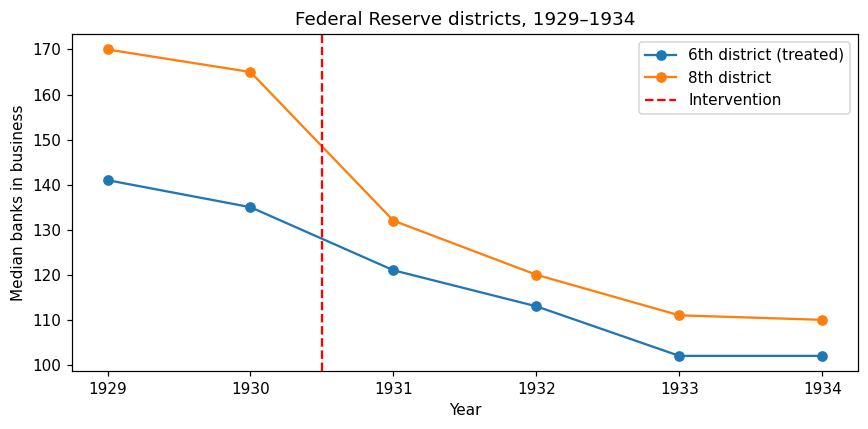

In [8]:
CAUSALPY_FILES = {
    "banks": "banks.csv",
    "covid": "deaths_and_temps_england_wales.csv",
    "drinking": "drinking.csv",
    "risk": "AJR2001.csv",
    "schoolReturns": "schoolingReturns.csv",
    "california_prop99": "california_prop99.csv",
}

def load_causalpy(name: str) -> pd.DataFrame:
    """Load a CausalPy example dataset.

    Uses causalpy.load_data when that package is installed. Otherwise reads
    the same CSV from the CausalPy GitHub data directory.
    """
    try:
        import causalpy as cp
        frame = cp.load_data(name)
        print(f"Loaded {name!r} with causalpy.load_data. Shape {frame.shape}.")
        return frame
    except ImportError:
        url = (
            "https://raw.githubusercontent.com/pymc-labs/CausalPy/main/causalpy/data/"
            + CAUSALPY_FILES[name]
        )
        frame = pd.read_csv(url)
        print(f"CausalPy is not installed. Loaded {name!r} from")
        print(url)
        print("Install the package with: pip install 'pycausalml[causalpy]'")
        print(f"Shape {frame.shape}.")
        return frame

banks = load_causalpy("banks")
yearly = (
    banks.filter(items=["bib6", "bib8", "year"])
    .rename(columns={"bib6": "sixth", "bib8": "eighth"})
    .groupby("year")
    .median()
)
print(yearly.round(1))

long = yearly.reset_index().melt(id_vars="year", var_name="district", value_name="banks_open")
long["treated"] = (long["district"] == "sixth").astype(float)
long["post"] = (long["year"] >= 1931).astype(float)

classic = long[long["year"].isin([1930, 1931])]
did_banks = DifferenceInDifferences(n_boot=400, random_state=0)
did_banks.fit(classic["banks_open"], classic["treated"], classic["post"])
print("\n1930 versus 1931:")
print(pd.Series(did_banks.summary()).round(2))
print("One row per cell fixes the interaction, so this bootstrap interval collapses.")

did_banks_full = DifferenceInDifferences(n_boot=400, random_state=1)
did_banks_full.fit(long["banks_open"], long["treated"], long["post"])
print("\nAll years, post = 1931 onward:")
print(pd.Series(did_banks_full.summary()).round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(yearly.index, yearly["sixth"], "o-", label="6th district (treated)")
ax.plot(yearly.index, yearly["eighth"], "o-", label="8th district")
ax.axvline(1930.5, color="red", ls="--", label="Intervention")
ax.set_ylabel("Median banks in business")
ax.set_xlabel("Year")
ax.set_title("Federal Reserve districts, 1929–1934")
ax.legend()
fig.tight_layout()
plt.show()


## Common Pitfalls

### 1. Violation of Parallel Trends

If treated and control groups were on different trajectories before treatment, DiD is biased. This often happens when struggling units get the intervention (negative selection) or high-performing units get it first (positive selection).

**Solution**: Use pre-trend checks and consider alternative methods (synthetic control, RDD) if parallel trends fails.

### 2. Contemporaneous Shocks

If something else happens to the treated group at the same time as the intervention (e.g., a competitor exits, a local event), DiD will attribute the combined effect to the intervention.

**Solution**: Maintain an intervention calendar and check for co-occurring events. Use multiple control groups or synthetic control to triangulate.

### 3. Wrong Clustering Level

Clustering at the wrong level (e.g., store instead of market) leads to incorrect standard errors.

**Solution**: Always cluster at the level of treatment assignment.

### 4. Including Post-Treatment Covariates

Adding variables that change after treatment (mediators) blocks part of the treatment effect and biases the estimate.

**Solution**: Only include pre-treatment or time-invariant covariates.

### 5. Few Treated Clusters

With few treated groups (< ~40), clustered standard errors are unreliable.

**Solution**: Use wild-cluster bootstrap, permutation tests, or aggregate to the treatment level.

## When to Use DiD

DiD is the right choice when:

- Treatment is assigned to **clear groups** at **known times**
- You have **pre- and post-period data** for both treated and control groups
- The **parallel trends assumption** is plausible (supported by pre-trend checks)
- Treatment timing is **simultaneous** (or you use event-study methods for staggered adoption)

Consider alternatives when:

- Parallel trends is violated → Synthetic control, RDD
- Treatment is assigned by a threshold → RDD
- Treatment is self-selected with confounding → IV, propensity methods
- Only one treated unit → Synthetic control

## Summary

DiD is a powerful and intuitive method for estimating causal effects when treatment is assigned to groups at known times. Its strength lies in the transparency of the parallel trends assumption and the ease of communicating results to stakeholders.

**Key takeaways:**

- DiD estimates the difference in changes between treated and control groups
- The identifying assumption is parallel trends — check it with pre-trend visualizations and formal tests
- Cluster standard errors at the level of treatment assignment
- Be cautious with staggered adoption — already-treated units are poor controls when effects change over time
- Chapter 6.5 reports the Bayesian interval for this estimator on the CausalPy banking panel
- Always probe the assumption with falsification tests


## Scientific Terminology

Plain-language definitions for the terms in this tutorial are in the [scientific terminology glossary](../00-scientific-terminology-glossary.qmd).
